In [1]:
!pip -q install kaggle mne eeglabio tensorflow scikit-learn pandas numpy scipy matplotlib seaborn

In [2]:
# CELL 1 — Windows path + Kaggle setup
import os
import shutil
from pathlib import Path

HOME = Path.home()   # usually C:\Users\U
DESKTOP = HOME / "Desktop"
WORK_ROOT = DESKTOP / "Shoili"

# Put your kaggle json here:
KAGGLE_JSON_SOURCE = WORK_ROOT / "kaggle (2).json"

# Kaggle expects this target:
KAGGLE_DIR = HOME / ".kaggle"
KAGGLE_JSON_TARGET = KAGGLE_DIR / "kaggle.json"

# All new folders/files will stay inside Desktop\Shoili
DOWNLOAD_BASE = WORK_ROOT / "openneuro_work"
ZIP_PATH = DOWNLOAD_BASE / "openneuro-ds004504.zip"
EXTRACT_DIR = DOWNLOAD_BASE / "openneuro_ds004504"
DATASET_ROOT = EXTRACT_DIR / "ds004504"
OUTPUT_ROOT = WORK_ROOT / "eeg_ad_hc_rebuild"

KAGGLE_DIR.mkdir(parents=True, exist_ok=True)
DOWNLOAD_BASE.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not KAGGLE_JSON_SOURCE.exists():
    raise FileNotFoundError(f"Kaggle JSON file not found: {KAGGLE_JSON_SOURCE}")

shutil.copy2(KAGGLE_JSON_SOURCE, KAGGLE_JSON_TARGET)

# Windows permission-friendly
try:
    os.chmod(KAGGLE_JSON_TARGET, 0o600)
except Exception:
    pass

print("kaggle.json configured at:", KAGGLE_JSON_TARGET)
print("Download folder:", DOWNLOAD_BASE)
print("Dataset root will be:", DATASET_ROOT)
print("Output root:", OUTPUT_ROOT)


kaggle.json configured at: C:\Users\U\.kaggle\kaggle.json
Download folder: C:\Users\U\Desktop\Shoili\openneuro_work
Dataset root will be: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild


In [3]:
# CELL 2 — Imports + config + GPU check
import os
import gc
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import (
    confusion_matrix, f1_score, accuracy_score, roc_auc_score, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model, layers, utils
from tensorflow.keras.callbacks import (
    CSVLogger, TerminateOnNaN, ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from tensorflow.keras.constraints import max_norm

from IPython.display import display

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
tf.get_logger().setLevel("ERROR")
mne.set_log_level("ERROR")

SEED = 42

def set_all_seeds(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_all_seeds(SEED)

# GPU memory growth
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled.")
    except RuntimeError as e:
        print("Could not set memory growth:", e)
else:
    print("No GPU detected by TensorFlow.")

CONFIG = {
    "dataset_root": DATASET_ROOT,
    "output_root": OUTPUT_ROOT,

    "analysis_channels": [
        "Fp1","Fp2","F7","F3","Fz","F4","F8",
        "T3","C3","Cz","C4","T4",
        "T5","P3","Pz","P4","T6","O1","O2"
    ],

    "target_sfreq": 256,
    "window_sec": 1,

    "task_name": "AD_vs_HC",
    "normalization": "channel_segment_zscore",

    "epochs": 20,
    "batch_size": 32,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,

    "n_splits": 10,
    "val_ratio": 0.10,

    "resume_training": True,
}

CONFIG["output_root"].mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("MNE:", mne.__version__)
print("Dataset root:", CONFIG["dataset_root"])
print("Output root:", CONFIG["output_root"])
print("GPUs found:", tf.config.list_physical_devices("GPU"))


GPU memory growth enabled.
TensorFlow: 2.10.0
MNE: 1.11.0
Dataset root: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# CELL 3 — Download + extract dataset (safe to rerun)
import os
import zipfile
import subprocess

if DATASET_ROOT.exists():
    print("Dataset already extracted at:", DATASET_ROOT)
else:
    if not ZIP_PATH.exists():
        print("Downloading dataset zip from Kaggle...")
        cmd = ["kaggle", "datasets", "download", "-d", "thngdngvn/openneuro-ds004504", "-p", str(DOWNLOAD_BASE)]
        result = subprocess.run(cmd, capture_output=True, text=True)
        print(result.stdout)
        if result.returncode != 0:
            print(result.stderr)
            raise RuntimeError("Kaggle download failed.")
    else:
        print("Zip already exists:", ZIP_PATH)

    print("Extracting zip...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)

    print("Extraction complete:", EXTRACT_DIR)

print("Exists participants.tsv:", (DATASET_ROOT / "participants.tsv").exists())
print("Sample top-level items:", sorted([p.name for p in DATASET_ROOT.iterdir()])[:20] if DATASET_ROOT.exists() else "dataset not found")


Dataset already extracted at: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Exists participants.tsv: True
Sample top-level items: ['derivatives', 'participants.tsv']


In [5]:
import os
import gc
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import (
    confusion_matrix, f1_score, accuracy_score, roc_auc_score, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model, layers, utils
from tensorflow.keras.callbacks import (
    CSVLogger, TerminateOnNaN, ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from tensorflow.keras.constraints import max_norm

from IPython.display import display

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
tf.get_logger().setLevel("ERROR")
mne.set_log_level("ERROR")

SEED = 42

def set_all_seeds(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_all_seeds(SEED)

CONFIG = {
    "dataset_root": DATASET_ROOT,
    "output_root": OUTPUT_ROOT,

    "analysis_channels": [
        "Fp1","Fp2","F7","F3","Fz","F4","F8",
        "T3","C3","Cz","C4","T4",
        "T5","P3","Pz","P4","T6","O1","O2"
    ],

    "target_sfreq": 256,
    "window_sec": 5,

    "task_name": "AD_vs_HC",
    "normalization": "channel_segment_zscore",

    "epochs": 20,
    "batch_size": 32,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,

    "n_splits": 10,
    "val_ratio": 0.10,

    "resume_training": True,
}

CONFIG["output_root"].mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("MNE:", mne.__version__)
print("Dataset root:", CONFIG["dataset_root"])
print("Output root:", CONFIG["output_root"])
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.10.0
MNE: 1.11.0
Dataset root: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
PARTICIPANTS_TSV = CONFIG["dataset_root"] / "participants.tsv"
DERIVATIVES_ROOT = CONFIG["dataset_root"] / "derivatives"

GROUP_MAP = {
    "A": "AD", "AD": "AD", "ALZHEIMER": "AD", "ALZHEIMERS": "AD",
    "C": "CN", "CN": "CN", "HC": "CN", "CONTROL": "CN",
    "HEALTHY": "CN", "COGNITIVELY NORMAL": "CN",
    "F": "FTD", "FTD": "FTD", "FRONTOTEMPORAL DEMENTIA": "FTD",
}

CHANNEL_ALIAS = {
    "FP1":"Fp1","FP2":"Fp2","F7":"F7","F3":"F3","FZ":"Fz","F4":"F4","F8":"F8",
    "T3":"T3","T7":"T3","C3":"C3","CZ":"Cz","C4":"C4","T4":"T4","T8":"T4",
    "T5":"T5","P7":"T5","P3":"P3","PZ":"Pz","P4":"P4","T6":"T6","P8":"T6",
    "O1":"O1","O2":"O2",
}

EXPECTED_COUNTS = {"AD": 36, "CN": 29, "FTD": 23}

def normalize_group(x):
    x = str(x).strip().upper().replace("_", " ").replace("-", " ")
    x = " ".join(x.split())
    if x in GROUP_MAP:
        return GROUP_MAP[x]
    raise ValueError(f"Unknown group label: {x}")

def load_participants():
    df = pd.read_csv(PARTICIPANTS_TSV, sep="\t")
    df["participant_id"] = df["participant_id"].astype(str).str.strip()

    group_col = next(
        (c for c in df.columns if c.lower() in {"group", "diagnosis", "label"}),
        None
    )
    if group_col is None:
        raise RuntimeError(f"No group/diagnosis column found. Columns: {list(df.columns)}")

    df["group"] = df[group_col].apply(normalize_group)
    return df[["participant_id", "group"]].copy()

def canon_ch(ch):
    return CHANNEL_ALIAS.get(str(ch).strip().upper().replace(" ", ""), ch)

def canonicalize_channels(raw):
    renames = {ch: canon_ch(ch) for ch in raw.ch_names if canon_ch(ch) != ch}
    if renames:
        raw.rename_channels(renames)
    return raw

def find_derivative_set(sub_id: str) -> Path:
    eeg_dir = DERIVATIVES_ROOT / sub_id / "eeg"
    preferred = eeg_dir / f"{sub_id}_task-eyesclosed_eeg.set"
    if preferred.exists():
        return preferred
    hits = sorted(eeg_dir.glob("*task-eyesclosed*_eeg.set"))
    if hits:
        return hits[0]
    raise FileNotFoundError(f"No derivative .set file found for {sub_id} in {eeg_dir}")

participants_all_df = load_participants()
counts_all = participants_all_df["group"].value_counts().to_dict()
for grp, exp in EXPECTED_COUNTS.items():
    got = int(counts_all.get(grp, 0))
    assert got == exp, f"Count mismatch for {grp}: expected {exp}, got {got}"

participants_df = participants_all_df[
    participants_all_df["group"].isin(["AD", "CN"])
].copy().reset_index(drop=True)

sub_to_group = dict(zip(participants_df["participant_id"], participants_df["group"]))

print("Participants loaded.")
print("All counts:", counts_all)
print("AD/CN only:", participants_df["group"].value_counts().to_dict())
display(participants_df.head())

Participants loaded.
All counts: {'AD': 36, 'CN': 29, 'FTD': 23}
AD/CN only: {'AD': 36, 'CN': 29}


,participant_id,group
0,sub-001,AD
1,sub-002,AD
2,sub-003,AD
3,sub-004,AD
4,sub-005,AD


In [7]:
def load_and_prepare_raw(sub_id: str):
    """
    Returns:
        data_uv: (19, n_samples) float32 in microvolts
    """
    path = find_derivative_set(sub_id)

    raw = mne.io.read_raw_eeglab(str(path), preload=True, verbose=False)
    raw = canonicalize_channels(raw)

    missing = [ch for ch in CONFIG["analysis_channels"] if ch not in raw.ch_names]
    if missing:
        raise RuntimeError(f"{sub_id}: missing channels after canonicalization: {missing}")

    raw = raw.copy().pick(CONFIG["analysis_channels"])
    raw.reorder_channels(CONFIG["analysis_channels"])

    if int(round(raw.info["sfreq"])) != CONFIG["target_sfreq"]:
        raw.resample(CONFIG["target_sfreq"], verbose=False)

    data_uv = (raw.get_data() * 1e6).astype(np.float32)

    del raw
    gc.collect()
    return data_uv

# quick sanity check
sample_ids = participants_df["participant_id"].head(2).tolist()
for sid in sample_ids:
    x = load_and_prepare_raw(sid)
    print(sid, x.shape, f"duration_sec={x.shape[1]/CONFIG['target_sfreq']:.1f}")
    del x
    gc.collect()

sub-001 (19, 153549) duration_sec=599.8
sub-002 (19, 203034) duration_sec=793.1


In [8]:
SEG_ROOT = CONFIG["output_root"] / "segments_5s_ad_hc"
META_ROOT = CONFIG["output_root"] / "metadata"
META_ROOT.mkdir(parents=True, exist_ok=True)

META_CSV = META_ROOT / "segment_metadata_5s.csv"
SUBJECT_AUDIT_CSV = META_ROOT / "subject_audit_5s.csv"

PAPER_COUNTS_5S = {"CN": 4808, "AD": 5807}

def segment_nonoverlap(data_uv: np.ndarray, sfreq: int, win_sec: int):
    win = int(win_sec * sfreq)
    n = data_uv.shape[1] // win
    if n == 0:
        return np.empty((0, data_uv.shape[0], win), dtype=np.float32)
    return np.stack([data_uv[:, i*win:(i+1)*win] for i in range(n)], axis=0).astype(np.float32)

def build_5s_segments(force_rebuild=False):
    if force_rebuild and SEG_ROOT.exists():
        shutil.rmtree(SEG_ROOT)

    SEG_ROOT.mkdir(parents=True, exist_ok=True)

    rows = []
    subject_rows = []

    for sub_id in sorted(participants_df["participant_id"].tolist()):
        group = sub_to_group[sub_id]
        data_uv = load_and_prepare_raw(sub_id)

        subject_rows.append({
            "subject_id": sub_id,
            "group": group,
            "n_channels": data_uv.shape[0],
            "n_samples": data_uv.shape[1],
            "duration_sec": round(data_uv.shape[1] / CONFIG["target_sfreq"], 2),
        })

        segs = segment_nonoverlap(data_uv, CONFIG["target_sfreq"], CONFIG["window_sec"])
        out_dir = SEG_ROOT / group
        out_dir.mkdir(parents=True, exist_ok=True)

        for i, seg in enumerate(segs):
            fpath = out_dir / f"{sub_id}_seg_{i:04d}.npy"
            if force_rebuild or (not fpath.exists()):
                np.save(fpath, seg)
            rows.append({
                "subject_id": sub_id,
                "group": group,
                "window": "5s",
                "filepath": str(fpath),
            })

        del data_uv, segs
        gc.collect()

    meta_df = pd.DataFrame(rows).sort_values(["group", "subject_id", "filepath"]).reset_index(drop=True)
    subject_df = pd.DataFrame(subject_rows).sort_values(["group", "subject_id"]).reset_index(drop=True)

    meta_df.to_csv(META_CSV, index=False)
    subject_df.to_csv(SUBJECT_AUDIT_CSV, index=False)
    return meta_df, subject_df

meta_df, subject_audit_df = build_5s_segments(force_rebuild=False)

count_df = meta_df.groupby("group").size().rename("generated_count").reset_index()
print("Generated 5s counts:")
display(count_df)

for grp, exp in PAPER_COUNTS_5S.items():
    got = int(count_df.loc[count_df["group"] == grp, "generated_count"].values[0])
    assert got == exp, f"5s count mismatch for {grp}: expected {exp}, got {got}"

print("Saved:")
print(META_CSV)
print(SUBJECT_AUDIT_CSV)

Generated 5s counts:


,group,generated_count
0,AD,5807
1,CN,4808


Saved:
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\metadata\segment_metadata_5s.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\metadata\subject_audit_5s.csv


In [9]:
def cleanup_memory():
    tf.keras.backend.clear_session()
    gc.collect()

def normalize_seg_channelwise(seg_ch_time: np.ndarray):
    seg = seg_ch_time.astype(np.float32, copy=False)
    mu = seg.mean(axis=1, keepdims=True)
    sd = seg.std(axis=1, keepdims=True)
    sd[sd < 1e-6] = 1.0
    return (seg - mu) / sd

def load_subset_arrays(subset_df: pd.DataFrame):
    """
    Returns:
      X: (N, time, ch, 1)
      y: (N,)
      subjects: (N,)
    """
    subset_df = subset_df.reset_index(drop=True)
    first = np.load(subset_df.iloc[0]["filepath"], mmap_mode="r")

    if first.ndim != 2:
        raise ValueError(f"Expected 2D segment array, got {first.shape}")

    # stored shape is (channels, time)
    n_ch, time_len = first.shape

    X = np.empty((len(subset_df), time_len, n_ch, 1), dtype=np.float32)
    y = subset_df["y"].to_numpy(np.int64)
    subjects = subset_df["subject_id"].astype(str).to_numpy()

    for i, row in enumerate(subset_df.itertuples(index=False)):
        seg = np.load(row.filepath)
        seg = normalize_seg_channelwise(seg)  # (ch, time)
        seg = seg.T[..., None]                # (time, ch, 1)
        X[i] = seg

    return X, y, subjects

def compute_metrics_from_probs(y_true, disease_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    disease_prob = np.asarray(disease_prob).astype(np.float32)
    y_pred = (disease_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    sensitivity = 100.0 * tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = 100.0 * tn / (tn + fp) if (tn + fp) > 0 else np.nan
    precision   = 100.0 * tp / (tp + fp) if (tp + fp) > 0 else np.nan
    f1          = float(f1_score(y_true, y_pred, zero_division=0))
    accuracy    = 100.0 * accuracy_score(y_true, y_pred)

    try:
        roc_auc = float(roc_auc_score(y_true, disease_prob))
    except Exception:
        roc_auc = np.nan

    return {
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1": f1,
        "accuracy": accuracy,
        "roc_auc": roc_auc,
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
    }

def find_best_threshold(y_true, disease_prob, metric="accuracy"):
    thresholds = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_score = -np.inf
    best_metrics = None

    for thr in thresholds:
        m = compute_metrics_from_probs(y_true, disease_prob, threshold=thr)
        bal_acc = 0.5 * (m["sensitivity"] + m["specificity"])

        if metric == "accuracy":
            score = m["accuracy"]
        elif metric == "f1":
            score = m["f1"]
        elif metric == "balanced_accuracy":
            score = bal_acc
        else:
            raise ValueError(metric)

        if score > best_score:
            best_score = score
            best_thr = float(thr)
            best_metrics = dict(m)
            best_metrics["balanced_accuracy"] = float(bal_acc)

    return best_thr, best_metrics

def append_df_csv(df: pd.DataFrame, path: Path):
    header = not path.exists()
    df.to_csv(path, mode="a", index=False, header=header)

def save_json(obj, path: Path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)

def make_callbacks(save_dir: Path, tag: str, patience_es=6, patience_lr=3):
    save_dir.mkdir(parents=True, exist_ok=True)
    return [
        TerminateOnNaN(),
        EarlyStopping(
            monitor="val_loss",
            patience=patience_es,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=patience_lr,
            min_lr=1e-5,
            verbose=1
        ),
        CSVLogger(str(save_dir / f"{tag}_history.csv"), append=False),
        ModelCheckpoint(
            filepath=str(save_dir / f"{tag}_best.weights.h5"),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),
    ]

In [10]:
# CELL 9 — Ablation model variant: dual branch without SE attention
def build_phase2_dual_branch_model_v2(input_shape,
                                      learning_rate=3e-4,
                                      label_smoothing=0.0,
                                      dropout_rate=0.35,
                                      weight_decay=1e-4):
    T, C, _ = input_shape
    sfreq = CONFIG["target_sfreq"]

    inp = layers.Input(shape=input_shape, name="eeg_input")

    # ---------------- TIME BRANCH ----------------
    t1 = layers.Conv2D(32, (32, 1), padding="same", use_bias=False, name="time_conv_32")(inp)
    t1 = layers.BatchNormalization(name="time_bn_32")(t1)
    t1 = layers.Activation("elu", name="time_act_32")(t1)

    t2 = layers.Conv2D(32, (64, 1), padding="same", use_bias=False, name="time_conv_64")(inp)
    t2 = layers.BatchNormalization(name="time_bn_64")(t2)
    t2 = layers.Activation("elu", name="time_act_64")(t2)

    t3 = layers.Conv2D(32, (128, 1), padding="same", use_bias=False, name="time_conv_128")(inp)
    t3 = layers.BatchNormalization(name="time_bn_128")(t3)
    t3 = layers.Activation("elu", name="time_act_128")(t3)

    t = layers.Concatenate(axis=-1, name="time_concat")([t1, t2, t3])

    t = layers.DepthwiseConv2D(
        kernel_size=(1, C),
        depth_multiplier=2,
        padding="valid",
        use_bias=False,
        depthwise_constraint=max_norm(1.0),
        name="time_spatial_dw"
    )(t)
    t = layers.BatchNormalization(name="time_spatial_bn")(t)
    t = layers.Activation("elu", name="time_spatial_act")(t)

    t = layers.AveragePooling2D(pool_size=(4, 1), name="time_pool1")(t)
    t = layers.SpatialDropout2D(0.20, name="time_drop1")(t)

    t = layers.SeparableConv2D(192, (16, 1), padding="same", use_bias=False, name="time_sepconv1")(t)
    t = layers.BatchNormalization(name="time_sep_bn1")(t)
    t = layers.Activation("elu", name="time_sep_act1")(t)
    t = layers.AveragePooling2D(pool_size=(4, 1), name="time_pool2")(t)
    t = layers.SpatialDropout2D(0.25, name="time_drop2")(t)

    t = layers.SeparableConv2D(256, (8, 1), padding="same", use_bias=False, name="time_sepconv2")(t)
    t = layers.BatchNormalization(name="time_sep_bn2")(t)
    t = layers.Activation("elu", name="time_sep_act2")(t)
    t = layers.AveragePooling2D(pool_size=(2, 1), name="time_pool3")(t)
    t = layers.SpatialDropout2D(dropout_rate, name="time_drop3")(t)

    t_embed = layers.GlobalAveragePooling2D(name="time_gap")(t)

    # ---------------- FREQUENCY BRANCH ----------------
    fx = layers.Lambda(lambda z: tf.squeeze(z, axis=-1), name="fft_squeeze")(inp)
    fx = layers.Lambda(lambda z: tf.transpose(z, perm=[0, 2, 1]), name="fft_transpose_ct")(fx)
    fx = layers.Lambda(lambda z: tf.signal.rfft(z), name="fft_rfft")(fx)
    fx = layers.Lambda(lambda z: tf.abs(z), name="fft_abs")(fx)

    max_bin = min((T // 2) + 1, int((45.0 * T) / sfreq) + 1)
    fx = layers.Lambda(lambda z: z[:, :, :max_bin], name="fft_clip_45hz")(fx)
    fx = layers.Lambda(lambda z: tf.math.log1p(z), name="fft_log1p")(fx)

    fx = layers.Lambda(lambda z: tf.transpose(z, perm=[0, 2, 1]), name="fft_transpose_fc")(fx)
    fx = layers.Lambda(lambda z: tf.expand_dims(z, axis=-1), name="fft_expand")(fx)

    f = layers.Conv2D(48, (7, 3), padding="same", use_bias=False, name="freq_conv1")(fx)
    f = layers.BatchNormalization(name="freq_bn1")(f)
    f = layers.Activation("elu", name="freq_act1")(f)
    f = layers.MaxPooling2D(pool_size=(2, 1), name="freq_pool1")(f)
    f = layers.Dropout(0.20, name="freq_drop1")(f)

    f = layers.Conv2D(96, (5, 3), padding="same", use_bias=False, name="freq_conv2")(f)
    f = layers.BatchNormalization(name="freq_bn2")(f)
    f = layers.Activation("elu", name="freq_act2")(f)
    f = layers.MaxPooling2D(pool_size=(2, 1), name="freq_pool2")(f)
    f = layers.Dropout(0.25, name="freq_drop2")(f)

    f = layers.Conv2D(192, (3, 3), padding="same", use_bias=False, name="freq_conv3")(f)
    f = layers.BatchNormalization(name="freq_bn3")(f)
    f = layers.Activation("elu", name="freq_act3")(f)
    f = layers.MaxPooling2D(pool_size=(2, 1), name="freq_pool3")(f)
    f = layers.Dropout(dropout_rate, name="freq_drop3")(f)

    f_embed = layers.GlobalAveragePooling2D(name="freq_gap")(f)

    # ---------------- FUSION HEAD ----------------
    z = layers.Concatenate(name="fusion_concat")([t_embed, f_embed])
    z = layers.Dense(768, activation="relu", name="fusion_fc1")(z)
    z = layers.Dropout(0.45, name="fusion_drop1")(z)
    z = layers.Dense(192, activation="relu", name="fusion_fc2")(z)
    z = layers.Dropout(0.30, name="fusion_drop2")(z)
    out = layers.Dense(2, activation="softmax", name="output")(z)

    model = Model(inp, out, name="ablation_dual_branch_without_se")

    optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate,
    clipnorm=1.0
    )

    model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
        metrics=["accuracy"]
    )
    return model

# parameter audit
meta_check = pd.read_csv(META_CSV).copy()
meta_check = meta_check[
    (meta_check["window"] == "5s") &
    (meta_check["group"].isin(["CN", "AD"]))
].reset_index(drop=True)

meta_check["y"] = meta_check["group"].map({"CN": 0, "AD": 1}).astype(np.int64)

tmp_X, tmp_y, tmp_sub = load_subset_arrays(meta_check.iloc[:8])

tmp_model = build_phase2_dual_branch_model_v2(
    input_shape=tmp_X.shape[1:],
    learning_rate=CONFIG["learning_rate"],
    label_smoothing=CONFIG["label_smoothing"],
    dropout_rate=0.35,
    weight_decay=CONFIG["weight_decay"]
)

print("Input shape:", tmp_X.shape[1:])
print("Model variant: Dual branch without SE attention")
print("Total params:", tmp_model.count_params())

del tmp_X, tmp_y, tmp_sub, tmp_model
cleanup_memory()


Input shape: (1280, 19, 1)
Model variant: Dual branch without SE attention
Total params: 834610


In [11]:
RUN_NAME = "ablation_5s_dual_branch_without_se_attention_10fold_batch16"
RUN_DIR = CONFIG["output_root"] / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

FOLD_METRICS_CSV = RUN_DIR / "fold_metrics.csv"
SEGMENT_PREDS_CSV = RUN_DIR / "segment_predictions.csv"

def make_json_safe(obj):
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): make_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [make_json_safe(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj

def save_json(obj, path: Path):
    with open(path, "w") as f:
        json.dump(make_json_safe(obj), f, indent=2)

meta = pd.read_csv(META_CSV).copy()
meta = meta[(meta["window"] == "5s") & (meta["group"].isin(["CN", "AD"]))].reset_index(drop=True)
meta["y"] = meta["group"].map({"CN": 0, "AD": 1}).astype(np.int64)
meta["subject_id"] = meta["subject_id"].astype(str)

print("Training rows:", len(meta))
print("Class counts:", meta["group"].value_counts().to_dict())

if CONFIG["resume_training"] and FOLD_METRICS_CSV.exists():
    done_df = pd.read_csv(FOLD_METRICS_CSV)
    done_folds = set(done_df["fold"].astype(int).tolist())
    print("Resuming. Completed folds:", sorted(done_folds))
else:
    done_folds = set()
    if FOLD_METRICS_CSV.exists():
        FOLD_METRICS_CSV.unlink()
    if SEGMENT_PREDS_CSV.exists():
        SEGMENT_PREDS_CSV.unlink()

skf = StratifiedKFold(
    n_splits=CONFIG["n_splits"],
    shuffle=True,
    random_state=SEED
)

start_all = time.time()

for fold_idx, (trainval_idx, test_idx) in enumerate(skf.split(meta, meta["y"]), start=1):
    if fold_idx in done_folds:
        print(f"Skipping fold {fold_idx} (already completed)")
        continue

    print("\n" + "=" * 90)
    print(f"PHASE-2 CLEAN 10s 10-FOLD | Fold {fold_idx}/{CONFIG['n_splits']}")
    print("=" * 90)

    fold_start = time.time()
    cleanup_memory()
    set_all_seeds(SEED + fold_idx)

    trainval_meta = meta.iloc[trainval_idx].reset_index(drop=True)
    test_meta = meta.iloc[test_idx].reset_index(drop=True)

    sss = StratifiedShuffleSplit(
        n_splits=1,
        test_size=CONFIG["val_ratio"],
        random_state=SEED + fold_idx
    )
    tr_idx, val_idx = next(sss.split(trainval_meta, trainval_meta["y"]))

    train_meta = trainval_meta.iloc[tr_idx].reset_index(drop=True)
    val_meta = trainval_meta.iloc[val_idx].reset_index(drop=True)

    print(f"train={len(train_meta)} | val={len(val_meta)} | test={len(test_meta)}")

    X_train, y_train, sub_train = load_subset_arrays(train_meta)
    X_val, y_val, sub_val = load_subset_arrays(val_meta)
    X_test, y_test, sub_test = load_subset_arrays(test_meta)

    print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

    class_weights_arr = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1]),
        y=y_train
    )
    class_weight = {0: float(class_weights_arr[0]), 1: float(class_weights_arr[1])}
    print("Class weights:", class_weight)

    model = build_phase2_dual_branch_model_v2(
        input_shape=X_train.shape[1:],
        learning_rate=CONFIG["learning_rate"],
        label_smoothing=CONFIG["label_smoothing"],
        dropout_rate=0.35,
        weight_decay=CONFIG["weight_decay"]
    )

    callbacks = make_callbacks(RUN_DIR, f"fold_{fold_idx:02d}")

    history = model.fit(
        X_train,
        utils.to_categorical(y_train, num_classes=2),
        validation_data=(X_val, utils.to_categorical(y_val, num_classes=2)),
        epochs=CONFIG["epochs"],
        batch_size=CONFIG["batch_size"],
        class_weight=class_weight,
        shuffle=True,
        verbose=1,
        callbacks=callbacks,
    )

    val_prob = model.predict(X_val, batch_size=CONFIG["batch_size"], verbose=0)[:, 1]
    best_thr, best_val_metrics = find_best_threshold(
        y_true=y_val,
        disease_prob=val_prob,
        metric="accuracy"
    )

    test_prob = model.predict(X_test, batch_size=CONFIG["batch_size"], verbose=0)[:, 1]
    test_default = compute_metrics_from_probs(y_test, test_prob, threshold=0.5)
    test_tuned = compute_metrics_from_probs(y_test, test_prob, threshold=best_thr)

    fold_minutes = (time.time() - fold_start) / 60.0

    print(
        f"best_thr={best_thr:.4f} | "
        f"default_acc={test_default['accuracy']:.2f}% | "
        f"tuned_acc={test_tuned['accuracy']:.2f}% | "
        f"auc={test_default['roc_auc']:.4f} | "
        f"fold_time={fold_minutes:.2f} min"
    )

    fold_row = pd.DataFrame([{
        "fold": fold_idx,
        "best_threshold": best_thr,
        "fold_time_min": fold_minutes,

        "default_accuracy": test_default["accuracy"],
        "default_sensitivity": test_default["sensitivity"],
        "default_specificity": test_default["specificity"],
        "default_precision": test_default["precision"],
        "default_f1": test_default["f1"],
        "default_roc_auc": test_default["roc_auc"],

        "tuned_accuracy": test_tuned["accuracy"],
        "tuned_sensitivity": test_tuned["sensitivity"],
        "tuned_specificity": test_tuned["specificity"],
        "tuned_precision": test_tuned["precision"],
        "tuned_f1": test_tuned["f1"],
        "tuned_roc_auc": test_tuned["roc_auc"],

        "val_best_accuracy": best_val_metrics["accuracy"],
        "val_best_sensitivity": best_val_metrics["sensitivity"],
        "val_best_specificity": best_val_metrics["specificity"],
        "val_best_precision": best_val_metrics["precision"],
        "val_best_f1": best_val_metrics["f1"],
        "val_best_roc_auc": best_val_metrics["roc_auc"],
    }])
    append_df_csv(fold_row, FOLD_METRICS_CSV)

    seg_pred_df = pd.DataFrame({
        "fold": fold_idx,
        "subject_id": sub_test,
        "y_true": y_test.astype(int),
        "prob_disease": test_prob.astype(float),
        "pred_default_0_5": (test_prob >= 0.5).astype(int),
        "pred_tuned": (test_prob >= best_thr).astype(int),
        "threshold_used": float(best_thr),
    })
    append_df_csv(seg_pred_df, SEGMENT_PREDS_CSV)

    del X_train, y_train, sub_train
    del X_val, y_val, sub_val
    del X_test, y_test, sub_test
    del val_prob, test_prob, history, model, seg_pred_df, fold_row
    cleanup_memory()

total_minutes = (time.time() - start_all) / 60.0
print(f"\nTotal elapsed time: {total_minutes:.2f} min")

fold_df = pd.read_csv(FOLD_METRICS_CSV)

summary_rows = []
for col in fold_df.columns:
    if col == "fold":
        continue
    vals = fold_df[col].astype(float)
    summary_rows.append({
        "metric": col,
        "mean": float(vals.mean()),
        "std": float(vals.std()),
        "min": float(vals.min()),
        "max": float(vals.max()),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RUN_DIR / "summary.csv", index=False)

print("\nMain metrics (default threshold = 0.5):")
display(summary_df[summary_df["metric"].isin([
    "default_accuracy",
    "default_sensitivity",
    "default_specificity",
    "default_precision",
    "default_f1",
    "default_roc_auc",
    "fold_time_min",
])])

print("\nSecondary metrics (tuned threshold):")
display(summary_df[summary_df["metric"].isin([
    "tuned_accuracy",
    "tuned_sensitivity",
    "tuned_specificity",
    "tuned_precision",
    "tuned_f1",
    "tuned_roc_auc",
    "best_threshold",
])])

print("\nSaved files:")
print(FOLD_METRICS_CSV)
print(SEGMENT_PREDS_CSV)
print(RUN_DIR / "summary.csv")

Training rows: 10615
Class counts: {'AD': 5807, 'CN': 4808}

PHASE-2 CLEAN 10s 10-FOLD | Fold 1/10
train=8597 | val=956 | test=1062
X_train: (8597, 1280, 19, 1) | X_val: (956, 1280, 19, 1) | X_test: (1062, 1280, 19, 1)
Class weights: {0: 1.1038777606574217, 1: 0.9139910695300871}
Epoch 1/20
269/269 [==============================] - ETA: 0s - loss: 0.4718 - accuracy: 0.7581
Epoch 1: val_loss improved from inf to 0.71123, saving model to C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_01_best.weights.h5
269/269 [==============================] - 37s 116ms/step - loss: 0.4718 - accuracy: 0.7581 - val_loss: 0.7112 - val_accuracy: 0.4550 - lr: 3.0000e-04
Epoch 2/20
269/269 [==============================] - ETA: 0s - loss: 0.2938 - accuracy: 0.8782
Epoch 2: val_loss improved from 0.71123 to 0.31287, saving model to C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_01_best

,metric,mean,std,min,max
1,fold_time_min,10.202271,0.227475,9.868203,10.560089
2,default_accuracy,97.598338,2.095491,93.502825,99.811499
3,default_sensitivity,98.346875,1.927368,93.803787,100.000000
4,default_specificity,96.694170,5.223140,85.654886,99.792100
5,default_precision,97.471765,3.865747,89.384615,99.823633
6,default_f1,0.978471,0.018140,0.943948,0.998282
7,default_roc_auc,0.999193,0.000575,0.998161,0.999756



Secondary metrics (tuned threshold):


,metric,mean,std,min,max
0,best_threshold,0.417000,0.329833,0.050000,0.940000
8,tuned_accuracy,98.653040,0.734675,97.457627,99.717248
9,tuned_sensitivity,99.276693,0.485761,98.620690,100.000000
10,tuned_specificity,97.899688,1.233406,96.049896,99.375000
11,tuned_precision,98.285228,0.992217,96.790541,99.486301
12,tuned_f1,0.987768,0.006631,0.976982,0.997425
13,tuned_roc_auc,0.999193,0.000575,0.998161,0.999756



Saved files:
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_metrics.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\ablation_5s_dual_branch_without_se_attention_10fold_batch16\segment_predictions.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\ablation_5s_dual_branch_without_se_attention_10fold_batch16\summary.csv


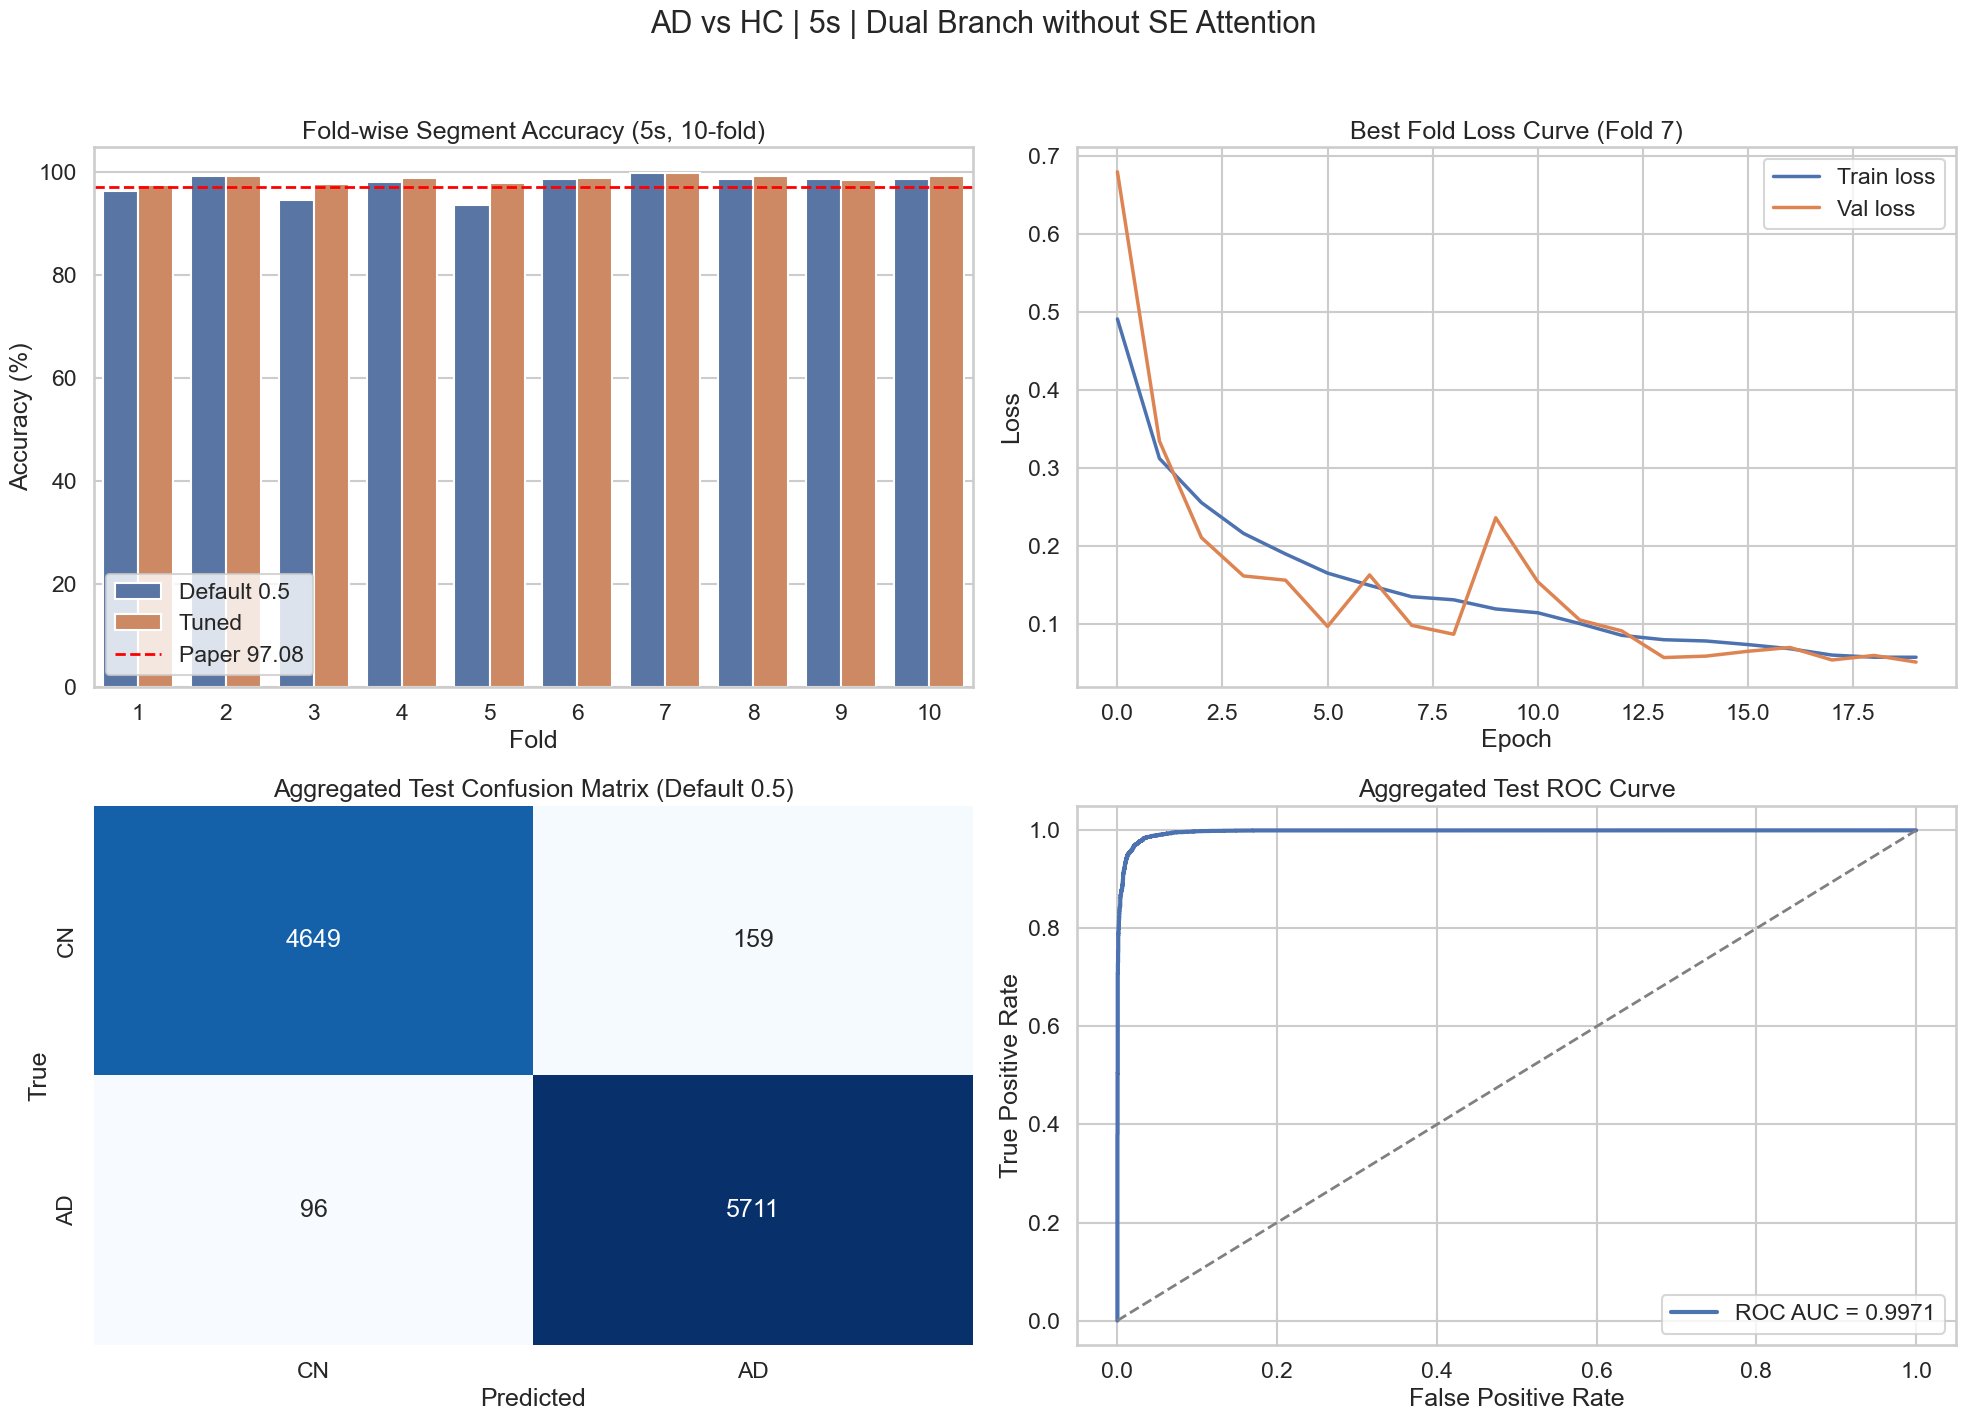

Saved figure: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\ablation_5s_dual_branch_without_se_attention_10fold_batch16\beautiful_summary_figure.png


In [12]:
sns.set_theme(style="whitegrid", context="talk")

fold_df = pd.read_csv(FOLD_METRICS_CSV)
pred_df = pd.read_csv(SEGMENT_PREDS_CSV)

# aggregated confusion matrix and ROC
y_true_all = pred_df["y_true"].to_numpy().astype(int)
prob_all = pred_df["prob_disease"].to_numpy().astype(float)
pred_all = pred_df["pred_default_0_5"].to_numpy().astype(int)

cm = confusion_matrix(y_true_all, pred_all, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fpr, tpr, _ = roc_curve(y_true_all, prob_all)
auc_all = roc_auc_score(y_true_all, prob_all)

# best fold history
best_fold = int(fold_df.loc[fold_df["default_accuracy"].idxmax(), "fold"])
history_path = RUN_DIR / f"fold_{best_fold:02d}_history.csv"
hist_df = pd.read_csv(history_path)

# 2x2 summary figure
fig, axes = plt.subplots(2, 2, figsize=(20, 14))

# --- panel 1: fold accuracies ---
acc_long = pd.DataFrame({
    "fold": np.concatenate([fold_df["fold"].values, fold_df["fold"].values]),
    "accuracy": np.concatenate([fold_df["default_accuracy"].values, fold_df["tuned_accuracy"].values]),
    "mode": ["Default 0.5"] * len(fold_df) + ["Tuned"] * len(fold_df),
})

sns.barplot(
    data=acc_long,
    x="fold",
    y="accuracy",
    hue="mode",
    ax=axes[0, 0]
)
axes[0, 0].axhline(97.08, ls="--", lw=2, color="red", label="Paper 97.08")
axes[0, 0].set_title("Fold-wise Segment Accuracy (5s, 10-fold)")
axes[0, 0].set_xlabel("Fold")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].legend()

# --- panel 2: best fold training history ---
axes[0, 1].plot(hist_df["epoch"], hist_df["loss"], label="Train loss", linewidth=2.5)
axes[0, 1].plot(hist_df["epoch"], hist_df["val_loss"], label="Val loss", linewidth=2.5)
axes[0, 1].set_title(f"Best Fold Loss Curve (Fold {best_fold})")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()

# --- panel 3: confusion matrix ---
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["CN", "AD"],
    yticklabels=["CN", "AD"],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Aggregated Test Confusion Matrix (Default 0.5)")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("True")

# --- panel 4: ROC curve ---
axes[1, 1].plot(fpr, tpr, linewidth=3, label=f"ROC AUC = {auc_all:.4f}")
axes[1, 1].plot([0, 1], [0, 1], linestyle="--", linewidth=2, color="gray")
axes[1, 1].set_title("Aggregated Test ROC Curve")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend(loc="lower right")

plt.suptitle("AD vs HC | 5s | Dual Branch without SE Attention", fontsize=22, y=1.02)
plt.tight_layout()

fig_path = RUN_DIR / "beautiful_summary_figure.png"
plt.savefig(fig_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

In [13]:
summary_df = pd.read_csv(RUN_DIR / "summary.csv")

main_summary = summary_df[summary_df["metric"].isin([
    "default_accuracy",
    "default_sensitivity",
    "default_specificity",
    "default_precision",
    "default_f1",
    "default_roc_auc",
    "fold_time_min",
])].copy()

secondary_summary = summary_df[summary_df["metric"].isin([
    "tuned_accuracy",
    "tuned_sensitivity",
    "tuned_specificity",
    "tuned_precision",
    "tuned_f1",
    "tuned_roc_auc",
    "best_threshold",
])].copy()

print("MAIN SUMMARY")
display(main_summary)

print("SECONDARY SUMMARY")
display(secondary_summary)

print("Paper target for 5s 10-fold segment accuracy: 97.08%")
print(" mean default accuracy:",
      float(main_summary.loc[main_summary["metric"] == "default_accuracy", "mean"].values[0]))

MAIN SUMMARY


,metric,mean,std,min,max
1,fold_time_min,10.202271,0.227475,9.868203,10.560089
2,default_accuracy,97.598338,2.095491,93.502825,99.811499
3,default_sensitivity,98.346875,1.927368,93.803787,100.000000
4,default_specificity,96.694170,5.223140,85.654886,99.792100
5,default_precision,97.471765,3.865747,89.384615,99.823633
6,default_f1,0.978471,0.018140,0.943948,0.998282
7,default_roc_auc,0.999193,0.000575,0.998161,0.999756


SECONDARY SUMMARY


,metric,mean,std,min,max
0,best_threshold,0.417000,0.329833,0.050000,0.940000
8,tuned_accuracy,98.653040,0.734675,97.457627,99.717248
9,tuned_sensitivity,99.276693,0.485761,98.620690,100.000000
10,tuned_specificity,97.899688,1.233406,96.049896,99.375000
11,tuned_precision,98.285228,0.992217,96.790541,99.486301
12,tuned_f1,0.987768,0.006631,0.976982,0.997425
13,tuned_roc_auc,0.999193,0.000575,0.998161,0.999756


Paper target for 5s 10-fold segment accuracy: 97.08%
 mean default accuracy: 97.5983375666278


In [14]:
# =========================
# FINAL AUDIT CELL
# Run this at the very end
# =========================

import os
import re
import json
import math
import glob
import hashlib
import warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

warnings.filterwarnings("ignore")


# ---------------------------------------------------
# 0) Helpers
# ---------------------------------------------------
def _print_header(title):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)

def _safe_read_csv(path):
    try:
        return pd.read_csv(path)
    except Exception as e:
        print(f"[WARN] Could not read CSV: {path}\n  -> {e}")
        return None

def _find_first_existing(paths):
    for p in paths:
        if p is not None and Path(p).exists():
            return Path(p)
    return None

def _normalize_colnames(df):
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df

def _pick_col(df, candidates):
    cols_lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols_lower:
            return cols_lower[cand.lower()]
    # partial match fallback
    for c in df.columns:
        cl = c.lower()
        for cand in candidates:
            if cand.lower() in cl:
                return c
    return None

def _infer_subject_col(df):
    return _pick_col(df, [
        "participant_id", "subject", "subject_id", "sub_id", "sub",
        "participant", "patient_id", "patient"
    ])

def _infer_group_col(df):
    return _pick_col(df, [
        "group", "label_name", "class_name", "diagnosis", "target_name"
    ])

def _infer_fold_col(df):
    return _pick_col(df, [
        "fold", "fold_id", "cv_fold", "kfold", "outer_fold"
    ])

def _infer_split_col(df):
    return _pick_col(df, [
        "split", "set", "subset", "phase", "partition"
    ])

def _infer_true_col(df):
    return _pick_col(df, [
        "y_true", "true", "label", "target", "y", "gt"
    ])

def _infer_pred_col(df):
    return _pick_col(df, [
        "y_pred", "pred", "prediction", "pred_label", "y_hat"
    ])

def _infer_prob_col(df):
    # preference for AD / positive class probability columns
    priority = [
        "prob_ad", "p_ad", "y_prob", "prob", "score", "positive_prob",
        "pred_prob", "proba", "ad_prob", "prob_1", "p1"
    ]
    col = _pick_col(df, priority)
    if col is not None:
        return col

    # fallback: any column that looks like probability for AD/class1
    for c in df.columns:
        cl = c.lower()
        if ("prob" in cl or "score" in cl or "proba" in cl) and ("ad" in cl or "1" in cl or "pos" in cl):
            return c
    return None

def _specificity_from_cm(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    if cm.shape != (2, 2):
        return np.nan
    tn, fp, fn, tp = cm.ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else np.nan

def _metric_pack(y_true, y_prob=None, y_pred=None):
    out = {}
    out["n"] = len(y_true)
    out["accuracy"] = accuracy_score(y_true, y_pred) if y_pred is not None else np.nan
    out["precision"] = precision_score(y_true, y_pred, zero_division=0) if y_pred is not None else np.nan
    out["sensitivity"] = recall_score(y_true, y_pred, zero_division=0) if y_pred is not None else np.nan
    out["specificity"] = _specificity_from_cm(y_true, y_pred) if y_pred is not None else np.nan
    out["f1"] = f1_score(y_true, y_pred, zero_division=0) if y_pred is not None else np.nan
    out["roc_auc"] = roc_auc_score(y_true, y_prob) if y_prob is not None and len(np.unique(y_true)) == 2 else np.nan
    return out

def _pretty_metric_dict(d):
    for k, v in d.items():
        if isinstance(v, (float, np.floating)):
            if k == "n":
                print(f"{k:>12}: {int(v)}")
            else:
                print(f"{k:>12}: {v:.6f}")
        else:
            print(f"{k:>12}: {v}")

def _find_candidate_files(root, patterns):
    root = Path(root)
    found = []
    for pat in patterns:
        found.extend(root.rglob(pat))
    # unique preserve order
    seen = set()
    out = []
    for p in found:
        rp = str(p.resolve())
        if rp not in seen:
            seen.add(rp)
            out.append(p)
    return out

def _make_segment_key(df):
    """
    Build the strongest available segment key from metadata-like columns.
    """
    df = df.copy()

    subj = _infer_subject_col(df)
    file_col = _pick_col(df, [
        "source_file", "file_path", "filepath", "eeg_file", "raw_file", "file"
    ])
    start_col = _pick_col(df, [
        "start_sample", "start_idx", "start", "onset_sample", "segment_start"
    ])
    end_col = _pick_col(df, [
        "end_sample", "end_idx", "end", "segment_end"
    ])
    start_sec_col = _pick_col(df, [
        "start_sec", "start_time", "onset_sec", "segment_start_sec"
    ])
    dur_col = _pick_col(df, [
        "duration_sec", "duration", "window_sec", "segment_duration_sec"
    ])
    window_col = _pick_col(df, [
        "window", "window_name", "segment_type"
    ])

    pieces = []
    if subj is not None:
        pieces.append(df[subj].astype(str))
    if file_col is not None:
        pieces.append(df[file_col].astype(str))
    if start_col is not None:
        pieces.append(df[start_col].astype(str))
    if end_col is not None:
        pieces.append(df[end_col].astype(str))
    if start_sec_col is not None:
        pieces.append(df[start_sec_col].astype(str).round(6) if np.issubdtype(df[start_sec_col].dtype, np.number) else df[start_sec_col].astype(str))
    if dur_col is not None:
        pieces.append(df[dur_col].astype(str))
    if window_col is not None:
        pieces.append(df[window_col].astype(str))

    if len(pieces) == 0:
        # weakest fallback: row hash
        base = df.astype(str).agg("|".join, axis=1)
    else:
        base = pieces[0]
        for p in pieces[1:]:
            base = base.astype(str) + "|" + p.astype(str)

    return base.rename("segment_key")


# ---------------------------------------------------
# 1) Resolve paths
# ---------------------------------------------------
_print_header("STEP 1 — Resolving paths")

OUTPUT_ROOT_LOCAL = None
META_CSV_LOCAL = None

try:
    OUTPUT_ROOT_LOCAL = OUTPUT_ROOT
except NameError:
    OUTPUT_ROOT_LOCAL = None

try:
    META_CSV_LOCAL = META_CSV
except NameError:
    META_CSV_LOCAL = None

# extra fallbacks
path_candidates = []
if OUTPUT_ROOT_LOCAL is not None:
    path_candidates.append(OUTPUT_ROOT_LOCAL)
path_candidates.extend([
    Path.cwd(),
    Path.home() / "Desktop" / "Shoili" / "eeg_ad_hc_rebuild",
])

audit_root = _find_first_existing(path_candidates)
if audit_root is None:
    raise FileNotFoundError("Could not locate OUTPUT_ROOT. Set OUTPUT_ROOT or run from the project folder.")

audit_root = Path(audit_root)
print("Audit root:", audit_root)

meta_candidates = []
if META_CSV_LOCAL is not None:
    meta_candidates.append(META_CSV_LOCAL)
meta_candidates.extend([
    audit_root / "metadata" / "segment_metadata_5s.csv",
    audit_root / "segment_metadata_5s.csv",
])

meta_csv = _find_first_existing(meta_candidates)
if meta_csv is None:
    print("[WARN] Metadata CSV not found. Some audits will be skipped.")
else:
    print("Metadata CSV:", meta_csv)


# ---------------------------------------------------
# 2) Metadata audit
# ---------------------------------------------------
meta_df = None
subject_col = None
group_col = None

if meta_csv is not None:
    _print_header("STEP 2 — Metadata audit")
    meta_df = _safe_read_csv(meta_csv)
    if meta_df is not None:
        meta_df = _normalize_colnames(meta_df)
        subject_col = _infer_subject_col(meta_df)
        group_col = _infer_group_col(meta_df)

        print("Rows in metadata:", len(meta_df))
        print("Columns:", list(meta_df.columns))
        print("Detected subject col:", subject_col)
        print("Detected group col  :", group_col)

        if subject_col is not None:
            print("Unique subjects:", meta_df[subject_col].nunique())
        if group_col is not None:
            print("Class counts:")
            print(meta_df[group_col].value_counts(dropna=False))

        meta_df["segment_key"] = _make_segment_key(meta_df)

        dup_exact = meta_df["segment_key"].duplicated().sum()
        print("Exact duplicate segment_key rows:", int(dup_exact))

        if dup_exact > 0:
            print("[WARN] Exact duplicate segments found in metadata.")
            display(meta_df.loc[meta_df["segment_key"].duplicated(keep=False)].head(10))

        # subject internal duplication summary
        if subject_col is not None:
            per_sub_counts = meta_df.groupby(subject_col).size().sort_values(ascending=False)
            print("\nTop subject segment counts:")
            display(per_sub_counts.head(10).rename("segment_count").to_frame())


# ---------------------------------------------------
# 3) Find split / prediction files
# ---------------------------------------------------
_print_header("STEP 3 — Searching for split / prediction artifacts")

candidate_csvs = _find_candidate_files(
    audit_root,
    patterns=[
        "*.csv",
        "*.tsv",
        "*.json"
    ]
)

interesting = []
for p in candidate_csvs:
    nm = p.name.lower()
    if any(k in nm for k in [
        "fold", "split", "pred", "prediction", "oof", "test",
        "val", "summary", "result", "metrics", "audit"
    ]):
        interesting.append(p)

print(f"Found {len(interesting)} candidate artifact files.")
for p in interesting[:30]:
    print(" -", p.relative_to(audit_root))

# try to load plausible split/pred csvs
loaded_tables = {}
for p in interesting:
    if p.suffix.lower() == ".csv":
        df = _safe_read_csv(p)
        if df is not None and len(df) > 0:
            loaded_tables[str(p)] = _normalize_colnames(df)

print(f"\nLoaded {len(loaded_tables)} CSV artifact tables.")


# ---------------------------------------------------
# 4) Split overlap audit (if split files exist)
# ---------------------------------------------------
_print_header("STEP 4 — Subject overlap / split leakage audit")

split_tables = []
for path_str, df in loaded_tables.items():
    fold_c = _infer_fold_col(df)
    split_c = _infer_split_col(df)
    subj_c = _infer_subject_col(df)
    if fold_c is not None and split_c is not None and subj_c is not None:
        split_tables.append((path_str, df, fold_c, split_c, subj_c))

if len(split_tables) == 0:
    print("[INFO] No explicit split table found with fold+split+subject columns.")
    print("       If your notebook keeps train/val/test subject lists only in memory, this audit cannot read them automatically.")
else:
    for path_str, df, fold_c, split_c, subj_c in split_tables:
        print(f"\nUsing split table: {path_str}")
        print(f"fold={fold_c} | split={split_c} | subject={subj_c}")

        # normalize split labels
        temp = df[[fold_c, split_c, subj_c]].copy()
        temp[split_c] = temp[split_c].astype(str).str.lower().str.strip()

        fold_ids = sorted(temp[fold_c].dropna().unique())
        overlap_rows = []

        for fd in fold_ids:
            d = temp[temp[fold_c] == fd]
            train_subs = set(d.loc[d[split_c].str.contains("train"), subj_c].astype(str))
            val_subs   = set(d.loc[d[split_c].str.contains("val"), subj_c].astype(str))
            test_subs  = set(d.loc[d[split_c].str.contains("test"), subj_c].astype(str))

            overlap_rows.append({
                "fold": fd,
                "n_train_subj": len(train_subs),
                "n_val_subj": len(val_subs),
                "n_test_subj": len(test_subs),
                "train∩val": len(train_subs & val_subs),
                "train∩test": len(train_subs & test_subs),
                "val∩test": len(val_subs & test_subs),
            })

        overlap_df = pd.DataFrame(overlap_rows)
        display(overlap_df)

        if ((overlap_df[["train∩val", "train∩test", "val∩test"]] > 0).any().any()):
            print("[RED FLAG] Subject overlap detected across train/val/test in at least one fold.")
        else:
            print("[OK] No subject overlap detected in this split table.")


# ---------------------------------------------------
# 5) Duplicate segment overlap across split/pred tables
# ---------------------------------------------------
_print_header("STEP 5 — Duplicate segment overlap audit")

# Try to attach segment_key to artifact tables if enough columns exist
segment_overlap_checked = False

for path_str, df in loaded_tables.items():
    fold_c = _infer_fold_col(df)
    split_c = _infer_split_col(df)
    subj_c = _infer_subject_col(df)

    if fold_c is None or split_c is None:
        continue

    # need metadata-like fields OR merge with metadata via row keys
    df_local = df.copy()
    try:
        df_local["segment_key"] = _make_segment_key(df_local)
    except Exception:
        continue

    if "segment_key" not in df_local.columns:
        continue

    segment_overlap_checked = True
    print(f"\nArtifact: {path_str}")
    temp = df_local[[fold_c, split_c, "segment_key"]].copy()
    temp[split_c] = temp[split_c].astype(str).str.lower().str.strip()

    fold_ids = sorted(temp[fold_c].dropna().unique())
    rows = []

    for fd in fold_ids:
        d = temp[temp[fold_c] == fd]
        train_seg = set(d.loc[d[split_c].str.contains("train"), "segment_key"].astype(str))
        val_seg   = set(d.loc[d[split_c].str.contains("val"), "segment_key"].astype(str))
        test_seg  = set(d.loc[d[split_c].str.contains("test"), "segment_key"].astype(str))

        rows.append({
            "fold": fd,
            "n_train_seg": len(train_seg),
            "n_val_seg": len(val_seg),
            "n_test_seg": len(test_seg),
            "train∩val": len(train_seg & val_seg),
            "train∩test": len(train_seg & test_seg),
            "val∩test": len(val_seg & test_seg),
        })

    seg_overlap_df = pd.DataFrame(rows)
    display(seg_overlap_df)

    if ((seg_overlap_df[["train∩val", "train∩test", "val∩test"]] > 0).any().any()):
        print("[RED FLAG] Exact segment overlap detected across splits.")
    else:
        print("[OK] No exact segment overlap detected in this artifact.")

if not segment_overlap_checked:
    print("[INFO] No split/prediction table had enough segment fields to check exact segment overlap automatically.")


# ---------------------------------------------------
# 6) Prediction-based audit
# ---------------------------------------------------
_print_header("STEP 6 — Prediction audit (segment-level vs subject-level)")

prediction_tables = []

for path_str, df in loaded_tables.items():
    y_true_c = _infer_true_col(df)
    prob_c   = _infer_prob_col(df)
    pred_c   = _infer_pred_col(df)
    subj_c   = _infer_subject_col(df)
    fold_c   = _infer_fold_col(df)

    # Need at least y_true and one of prob/pred
    if y_true_c is not None and (prob_c is not None or pred_c is not None):
        prediction_tables.append((path_str, df, y_true_c, prob_c, pred_c, subj_c, fold_c))

if len(prediction_tables) == 0:
    print("[INFO] No prediction CSV automatically found.")
    print("       If predictions only existed in memory and were not saved, this part cannot run.")
else:
    for path_str, df, y_true_c, prob_c, pred_c, subj_c, fold_c in prediction_tables:
        print(f"\nPrediction file: {path_str}")
        print(f"y_true={y_true_c} | prob={prob_c} | pred={pred_c} | subject={subj_c} | fold={fold_c}")

        d = df.copy()

        # Clean labels to 0/1 if possible
        def _to01(s):
            if pd.api.types.is_numeric_dtype(s):
                vals = pd.Series(s).astype(float)
                if set(np.unique(vals.dropna())) <= {0, 1}:
                    return vals.astype(int)
                return vals
            s2 = s.astype(str).str.strip().str.upper()
            mapper = {
                "CN": 0, "HC": 0, "CONTROL": 0, "HEALTHY": 0, "0": 0,
                "AD": 1, "ALZHEIMER": 1, "1": 1
            }
            mapped = s2.map(mapper)
            return mapped

        d["_y_true"] = _to01(d[y_true_c])

        if prob_c is not None:
            d["_y_prob"] = pd.to_numeric(d[prob_c], errors="coerce")
        else:
            d["_y_prob"] = np.nan

        if pred_c is not None:
            d["_y_pred"] = _to01(d[pred_c])
        else:
            d["_y_pred"] = np.where(d["_y_prob"] >= 0.5, 1, 0)

        d = d.dropna(subset=["_y_true", "_y_pred"]).copy()
        d["_y_true"] = d["_y_true"].astype(int)
        d["_y_pred"] = d["_y_pred"].astype(int)

        # segment-level
        seg_metrics = _metric_pack(
            d["_y_true"].values,
            y_prob=d["_y_prob"].values if d["_y_prob"].notna().sum() > 0 else None,
            y_pred=d["_y_pred"].values
        )

        print("\nSegment-level metrics")
        _pretty_metric_dict(seg_metrics)

        # subject-level
        if subj_c is not None:
            s = d.copy()
            s["_subject"] = s[subj_c].astype(str)

            agg = {"_y_true": "first", "_y_pred": "mean"}
            if s["_y_prob"].notna().sum() > 0:
                agg["_y_prob"] = "mean"

            sub_df = s.groupby("_subject", as_index=False).agg(agg)

            # if pred was mean of hard labels, threshold at 0.5
            sub_df["_y_pred_bin"] = (sub_df["_y_pred"] >= 0.5).astype(int)

            sub_metrics = _metric_pack(
                sub_df["_y_true"].values.astype(int),
                y_prob=sub_df["_y_prob"].values if "_y_prob" in sub_df.columns else None,
                y_pred=sub_df["_y_pred_bin"].values.astype(int)
            )

            print("\nSubject-level metrics (mean prob / majority-style aggregation)")
            _pretty_metric_dict(sub_metrics)

            # gap summary
            print("\nSegment vs Subject gap")
            for k in ["accuracy", "precision", "sensitivity", "specificity", "f1", "roc_auc"]:
                sv = seg_metrics.get(k, np.nan)
                uv = sub_metrics.get(k, np.nan)
                if pd.notna(sv) and pd.notna(uv):
                    print(f"{k:>12}: segment={sv:.6f} | subject={uv:.6f} | gap={sv-uv:+.6f}")

            # highly confident separation check
            if "_y_prob" in sub_df.columns:
                print("\nPer-subject mean probability summary")
                display(sub_df[["_subject", "_y_true", "_y_prob"]].sort_values("_y_prob").head(10))
                display(sub_df[["_subject", "_y_true", "_y_prob"]].sort_values("_y_prob", ascending=False).head(10))

                p0 = sub_df.loc[sub_df["_y_true"] == 0, "_y_prob"]
                p1 = sub_df.loc[sub_df["_y_true"] == 1, "_y_prob"]
                if len(p0) > 0 and len(p1) > 0:
                    print(f"Class-0 subject mean prob range: [{p0.min():.6f}, {p0.max():.6f}]")
                    print(f"Class-1 subject mean prob range: [{p1.min():.6f}, {p1.max():.6f}]")
                    if p0.max() < p1.min():
                        print("[NOTE] Perfect subject-level probability separation observed.")
                        print("       This can mean either an extremely strong model or possible shortcut/leakage.")
        else:
            print("[INFO] Subject column missing, so subject-level audit skipped.")

        # fold-wise test subject uniqueness
        if subj_c is not None and fold_c is not None:
            chk = d[[subj_c, fold_c]].drop_duplicates()
            repeated_subs = chk[subj_c].value_counts()
            repeated_subs = repeated_subs[repeated_subs > 1]
            if len(repeated_subs) > 0:
                print("\n[WARN] Same subject appears in test/prediction records across multiple folds:")
                display(repeated_subs.head(20).rename("n_folds").to_frame())
            else:
                print("\n[OK] Each subject appears in only one fold in this prediction file.")


# ---------------------------------------------------
# 7) Near-duplicate audit from metadata only
# ---------------------------------------------------
_print_header("STEP 7 — Near-duplicate audit from metadata timing fields")

if meta_df is None:
    print("[INFO] Metadata not available. Skipping near-duplicate timing audit.")
else:
    subj_c = subject_col
    file_c = _pick_col(meta_df, ["source_file", "file_path", "filepath", "eeg_file", "raw_file", "file"])
    start_c = _pick_col(meta_df, ["start_sample", "start_idx", "start", "onset_sample", "segment_start"])
    start_sec_c = _pick_col(meta_df, ["start_sec", "start_time", "onset_sec", "segment_start_sec"])
    win_c = _pick_col(meta_df, ["window", "window_name", "segment_type"])

    if subj_c is None:
        print("[INFO] No subject column. Skipping this part.")
    else:
        tmp = meta_df.copy()

        # near-dup key based on rounded timing
        parts = [tmp[subj_c].astype(str)]
        if file_c is not None:
            parts.append(tmp[file_c].astype(str))
        if start_c is not None:
            # exact same starting sample
            parts.append(tmp[start_c].astype(str))
        elif start_sec_c is not None:
            # rounded start time
            parts.append(pd.to_numeric(tmp[start_sec_c], errors="coerce").round(2).astype(str))
        if win_c is not None:
            parts.append(tmp[win_c].astype(str))

        near_key = parts[0]
        for p in parts[1:]:
            near_key = near_key.astype(str) + "|" + p.astype(str)

        tmp["near_key"] = near_key
        near_dups = tmp["near_key"].duplicated().sum()

        print("Near-duplicate rows by subject+file+start(+window):", int(near_dups))
        if near_dups > 0:
            print("[WARN] Near-duplicate timing rows exist.")
            display(tmp.loc[tmp["near_key"].duplicated(keep=False)].head(10))
        else:
            print("[OK] No near-duplicate timing rows found with available metadata fields.")


# ---------------------------------------------------
# 8) Final interpretation rules
# ---------------------------------------------------
_print_header("STEP 8 — Final automated interpretation")

flags = []

# metadata duplicates
if meta_df is not None and "segment_key" in meta_df.columns:
    if meta_df["segment_key"].duplicated().sum() > 0:
        flags.append("Exact duplicate segments exist in metadata.")

# split overlaps
for path_str, df in loaded_tables.items():
    fold_c = _infer_fold_col(df)
    split_c = _infer_split_col(df)
    subj_c = _infer_subject_col(df)
    if fold_c is not None and split_c is not None and subj_c is not None:
        temp = df[[fold_c, split_c, subj_c]].copy()
        temp[split_c] = temp[split_c].astype(str).str.lower().str.strip()
        for fd in temp[fold_c].dropna().unique():
            d = temp[temp[fold_c] == fd]
            train_subs = set(d.loc[d[split_c].str.contains("train"), subj_c].astype(str))
            val_subs   = set(d.loc[d[split_c].str.contains("val"), subj_c].astype(str))
            test_subs  = set(d.loc[d[split_c].str.contains("test"), subj_c].astype(str))
            if len(train_subs & val_subs) > 0 or len(train_subs & test_subs) > 0 or len(val_subs & test_subs) > 0:
                flags.append(f"Subject overlap found in split table: {Path(path_str).name}")
                break

if len(flags) == 0:
    print("[GOOD] No direct smoking gun was found by this automatic audit.")
    print("       That still does NOT prove absence of leakage; it only means this cell did not catch one.")
    print("       If subject-level metrics also remain very high and overlaps are zero, your result becomes more defensible.")
else:
    print("[RED FLAGS FOUND]")
    for i, f in enumerate(flags, 1):
        print(f"{i}. {f}")

print("\nDone.")


STEP 1 — Resolving paths
Audit root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild
Metadata CSV: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\metadata\segment_metadata_5s.csv

STEP 2 — Metadata audit
Rows in metadata: 10615
Columns: ['subject_id', 'group', 'window', 'filepath']
Detected subject col: subject_id
Detected group col  : group
Unique subjects: 65
Class counts:
group
AD    5807
CN    4808
Name: count, dtype: int64
Exact duplicate segment_key rows: 0

Top subject segment counts:


,segment_count
subject_id,
sub-010,256
sub-031,230
sub-048,197
sub-016,194
sub-040,193
sub-034,193
sub-042,192
sub-014,186
sub-021,184



STEP 3 — Searching for split / prediction artifacts
Found 14 candidate artifact files.
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_01_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_02_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_03_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_04_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_05_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_06_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_07_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_08_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_09_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_10_history.csv
 - ablation_5s_dual_branch_without_se_attention_10fold_batch16\fold_metrics.csv
 -

,_subject,_y_true,_y_prob
53,sub-054,0,0.002192
63,sub-064,0,0.002931
40,sub-041,0,0.005235
54,sub-055,0,0.007237
45,sub-046,0,0.009789
36,sub-037,0,0.015768
59,sub-060,0,0.015846
46,sub-047,0,0.017371
41,sub-042,0,0.017382
52,sub-053,0,0.019042


,_subject,_y_true,_y_prob
27,sub-028,1,0.999971
23,sub-024,1,0.999941
28,sub-029,1,0.999619
26,sub-027,1,0.999544
3,sub-004,1,0.999452
29,sub-030,1,0.998376
17,sub-018,1,0.998332
6,sub-007,1,0.996354
8,sub-009,1,0.993820
16,sub-017,1,0.993791


Class-0 subject mean prob range: [0.002192, 0.131683]
Class-1 subject mean prob range: [0.885059, 0.999971]
[NOTE] Perfect subject-level probability separation observed.
       This can mean either an extremely strong model or possible shortcut/leakage.

[WARN] Same subject appears in test/prediction records across multiple folds:


,n_folds
subject_id,
sub-001,10
sub-034,10
sub-036,10
sub-037,10
sub-038,10
sub-039,10
sub-040,10
sub-041,10
sub-042,10



STEP 7 — Near-duplicate audit from metadata timing fields
Near-duplicate rows by subject+file+start(+window): 0
[OK] No near-duplicate timing rows found with available metadata fields.

STEP 8 — Final automated interpretation
[GOOD] No direct smoking gun was found by this automatic audit.
       That still does NOT prove absence of leakage; it only means this cell did not catch one.
       If subject-level metrics also remain very high and overlaps are zero, your result becomes more defensible.

Done.


In [15]:
# ==========================================
# TARGETED PREDICTION FILE AUDIT
# ==========================================

import pandas as pd
from pathlib import Path

# ---- 1) Load prediction file ----
pred_path = Path(r"C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\ablation_5s_dual_branch_without_se_attention_10fold_batch16\segment_predictions.csv")

df = pd.read_csv(pred_path)
print("Loaded:", pred_path)
print("Shape:", df.shape)
print("Columns:", list(df.columns))


# ---- 2) Detect columns ----
def find_col(candidates):
    for c in df.columns:
        for cand in candidates:
            if cand.lower() in c.lower():
                return c
    return None

subject_col = find_col(["subject", "participant"])
fold_col    = find_col(["fold"])
split_col   = find_col(["split", "set", "subset"])
y_true_col  = find_col(["y_true", "label", "target"])
y_pred_col  = find_col(["pred"])
prob_col    = find_col(["prob", "score"])

print("\nDetected:")
print("subject:", subject_col)
print("fold   :", fold_col)
print("split  :", split_col)


# ---- 3) If split column exists ----
if split_col is not None:
    print("\nUnique split values:", df[split_col].unique())

    # Try to isolate test only
    test_df = df[df[split_col].astype(str).str.lower().str.contains("test")]

    print("Test-only rows:", len(test_df))

else:
    print("\n[WARNING] No split column found → file likely contains mixed predictions")
    test_df = df.copy()


# ---- 4) Subject per fold check ----
print("\n=== SUBJECT-FOLD DISTRIBUTION ===")

sub_fold = test_df.groupby(subject_col)[fold_col].nunique()
print(sub_fold.describe())

print("\nSubjects appearing in multiple folds:")
multi = sub_fold[sub_fold > 1]
print(multi.head(20))

if len(multi) == 0:
    print("\n[GOOD] Each subject appears in ONLY ONE fold (correct CV behavior)")
else:
    print("\n[RED FLAG] Same subject appears in multiple folds")


# ---- 5) Fold-wise subject uniqueness ----
print("\n=== PER-FOLD SUBJECT CHECK ===")

fold_groups = test_df.groupby(fold_col)[subject_col].unique()

all_subjects = set()
overlap_flag = False

for f, subs in fold_groups.items():
    subs = set(subs)
    overlap = all_subjects.intersection(subs)

    print(f"Fold {f}: {len(subs)} subjects | overlap with previous folds: {len(overlap)}")

    if len(overlap) > 0:
        overlap_flag = True

    all_subjects.update(subs)

if not overlap_flag:
    print("\n[GOOD] No subject overlap across folds (clean CV)")
else:
    print("\n[RED FLAG] Subject overlap exists across folds")


# ---- 6) Final verdict ----
print("\n" + "="*60)

if split_col is None:
    print("❗ File mixes train/val/test predictions → cannot trust metrics directly")
elif len(multi) > 0 or overlap_flag:
    print("❗ Subject leakage likely (same subject in multiple test folds)")
else:
    print("✅ Cross-validation looks clean → results more trustworthy")

print("="*60)

Loaded: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\ablation_5s_dual_branch_without_se_attention_10fold_batch16\segment_predictions.csv
Shape: (10615, 7)
Columns: ['fold', 'subject_id', 'y_true', 'prob_disease', 'pred_default_0_5', 'pred_tuned', 'threshold_used']

Detected:
subject: subject_id
fold   : fold
split  : None

[WARNING] No split column found → file likely contains mixed predictions

=== SUBJECT-FOLD DISTRIBUTION ===
count    65.0
mean     10.0
std       0.0
min      10.0
25%      10.0
50%      10.0
75%      10.0
max      10.0
Name: fold, dtype: float64

Subjects appearing in multiple folds:
subject_id
sub-001    10
sub-002    10
sub-003    10
sub-004    10
sub-005    10
sub-006    10
sub-007    10
sub-008    10
sub-009    10
sub-010    10
sub-011    10
sub-012    10
sub-013    10
sub-014    10
sub-015    10
sub-016    10
sub-017    10
sub-018    10
sub-019    10
sub-020    10
Name: fold, dtype: int64

[RED FLAG] Same subject appears in multiple folds

=== PER-FOLD SUBJECT C